# 02 · Models

Predict at first satellite detection whether a California fire grows past 1,000 acres.

Lineup: baselines → logistic regression → XGBoost (main) → EBM → CatBoost

**Rule for this notebook:** compare and tune everything on **validation** (2021–2022). The **test** years (2023–2024) stay locked until the very end, and we score them once.

## Load the model-ready data

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

D = Path("../data/processed/model_ready")

def load(split):
    X = pd.read_csv(D / f"X_{split}.csv")
    X_scaled = pd.read_csv(D / f"X_{split}_scaled.csv")
    y = pd.read_csv(D / f"y_{split}.csv").iloc[:, 0]
    info = pd.read_csv(D / f"info_{split}.csv")
    return X, X_scaled, y, info

X_train, X_train_scaled, y_train, info_train = load("train")
X_val, X_val_scaled, y_val, info_val = load("val")
X_test, X_test_scaled, y_test, info_test = load("test")

print(X_train.shape, X_val.shape, X_test.shape)

(3603, 46) (938, 46) (1024, 46)


## Scoring helper

In [3]:
from sklearn.metrics import average_precision_score, roc_auc_score

results = []  # every model we score gets added here, so we can compare them in one table

def evaluate(name, y_true, scores, info, n_boot=1000, seed=0):
    """Score a model. `scores` = predicted chance of a big fire for each fire (higher = more likely big).

    PR-AUC (average precision): main score. Chance level = share of big fires.
    ROC-AUC: secondary score. Chance level = 0.5.
    Hard cases: fires still <= 3 pixels when first seen.
    95% CI: bootstrap, i.e. resample the fires 1,000 times to see how much PR-AUC wobbles.
    """
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    hard = info["hard_case"].values == 1

    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].sum() > 0:
            boot.append(average_precision_score(y_true[i], scores[i]))

    row = {
        "model": name,
        "PR-AUC": average_precision_score(y_true, scores),
        "PR-AUC 95% CI": f"{np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f}",
        "ROC-AUC": roc_auc_score(y_true, scores),
        "hard PR-AUC": average_precision_score(y_true[hard], scores[hard]),
        "hard ROC-AUC": roc_auc_score(y_true[hard], scores[hard]),
    }
    results = [r for r in globals()["results"] if r["model"] != name]  # re-running a model replaces its row
    results.append(row)
    globals()["results"] = results
    return pd.DataFrame(results).set_index("model").round(3)

print(f"Chance level on validation: PR-AUC = {y_val.mean():.3f} (all fires), "
      f"{y_val[info_val.hard_case == 1].mean():.3f} (hard cases)")

Chance level on validation: PR-AUC = 0.057 (all fires), 0.030 (hard cases)


## Step 1 · Baselines

In [4]:
# Baseline A: rank fires by first-pass pixel count alone (no model at all)

evaluate("pixels only", y_val, X_val["fp_n_pixels"], info_val)

# Baseline B: a tiny decision tree on just 2 inputs, like Coffield et al. 2019
from sklearn.tree import DecisionTreeClassifier
DT = DecisionTreeClassifier(max_depth=3, random_state=0)

DT.fit(X_train[["fp_n_pixels", "erc_prev"]], y_train)
scores = DT.predict_proba(X_val[["fp_n_pixels", "erc_prev"]])[:, 1]
evaluate("2-var tree", y_val, scores, info_val)



,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599


In [5]:
## Step 2 · Logistic regression
from sklearn.linear_model import LogisticRegression

LR = LogisticRegression(C=0.1, max_iter=2000)
#   C = how strongly to keep the weights small (smaller C = simpler model, less overfitting)
#   max_iter = give it enough steps to finish learning

LR.fit(X_train_scaled,y_train)
# Fit it on the SCALED training data (X_train_scaled) and y_train

scores = LR.predict_proba(X_val_scaled)[:, 1]

evaluate("logistic regression", y_val, scores, info_val)
# Scores on the SCALED validation data: predict_proba(...)[:, 1], same as the tree


# evaluate("logistic regression", ...)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599
logistic regression,0.477,0.342–0.619,0.916,0.329,0.897


In [6]:
## Step 3 · XGBoost
from xgboost import XGBClassifier

XGB = XGBClassifier(random_state = 0)
# First try: default settings, just XGBClassifier(random_state=0)
# random_state fixes the randomness so you get the same result every run

XGB.fit(X_train, y_train)

scores = XGB.predict_proba(X_val)[:, 1]

evaluate("XGBoost (default)", y_val, scores, info_val)

# Fit on X_train (NOT scaled) and y_train


# predict_proba on X_val -> [:, 1] -> evaluate("XGBoost (default)", ...)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599
logistic regression,0.477,0.342–0.619,0.916,0.329,0.897
XGBoost (default),0.443,0.317–0.583,0.907,0.328,0.884


In [7]:
# Step 3b · XGBoost with gentler settings
# max_depth=3          -> shallower trees, can't memorize single fires as easily
# learning_rate=0.05   -> each tree corrects only a little, so more trees are needed
# n_estimators=300     -> number of trees
# subsample=0.8        -> each tree sees a random 80% of the fires
# colsample_bytree=0.8 -> each tree sees a random 80% of the inputs
# random_state=0
# fit, predict_proba on X_val, evaluate("XGBoost (tuned by hand)", ...)

XGB_modified = XGBClassifier(max_depth = 3, learning_rate = 0.05, n_estimators = 300, subsample = 0.8, colsample_bytree = 0.8, random_state = 0)

XGB_modified.fit(X_train, y_train)
scores = XGB_modified.predict_proba(X_val)[:, 1]

evaluate("XGBoost (modified)", y_val, scores, info_val)

,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599
logistic regression,0.477,0.342–0.619,0.916,0.329,0.897
XGBoost (default),0.443,0.317–0.583,0.907,0.328,0.884
XGBoost (modified),0.477,0.347–0.635,0.925,0.332,0.906


In [8]:
## Step 3c · Tune XGBoost with randomized search
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut

# Ranges to search. Each try picks one random value from each range.
#   randint(a, b)     -> whole number from a to b-1
#   uniform(a, w)     -> decimal between a and a+w
#   loguniform(a, b)  -> decimal between a and b, spread evenly on a log scale (good for rates)
search_space = {
    "n_estimators": randint(100, 800),        # number of trees
    "max_depth": randint(2, 6),               # tree depth: 2, 3, 4 or 5
    "learning_rate": loguniform(0.01, 0.2),   # how much each tree corrects
    "subsample": uniform(0.6, 0.4),           # share of fires each tree sees: 0.6-1.0
    "colsample_bytree": uniform(0.4, 0.6),    # share of inputs each tree sees: 0.4-1.0
    "min_child_weight": randint(1, 20),       # bigger = a leaf needs more fires, so it's harder to memorize single fires
    "reg_lambda": loguniform(0.1, 20),        # penalty that keeps tree outputs small
}

# Cross-validation: train on 8 years, score on the 9th, repeat for all 9 training years
LOGO = LeaveOneGroupOut()


R_Search = RandomizedSearchCV(
    XGBClassifier(random_state=0, n_jobs=4),   # the model to tune
    search_space,
    n_iter=40,                       # how many random combinations to try
    scoring="average_precision",     # = PR-AUC, our main score
    cv = LOGO,                          # the LeaveOneGroupOut from above
    random_state=0,                  # same random tries every time you run it
    n_jobs=2,                        # run 2 tries at once (with n_jobs=4 inside XGBoost -> uses 8 cores)
    verbose=1,                       # print progress
)

R_Search.fit(X_train, y_train, groups = info_train["year"])


# Fit the search on X_train, y_train. It also needs groups=info_train["year"]
# so LeaveOneGroupOut knows which fires belong to which year.
# (This is the slow part: 40 tries x 9 years = 360 fits, a few minutes)


print(R_Search.best_params_)            
print(round(R_Search.best_score_, 3))     

R_Search.best_estimator_

Fitting 9 folds for each of 40 candidates, totalling 360 fits
{'colsample_bytree': np.float64(0.8683175057718733), 'learning_rate': np.float64(0.014252090642467935), 'max_depth': 2, 'min_child_weight': 2, 'n_estimators': 365, 'reg_lambda': np.float64(1.7238994052457324), 'subsample': np.float64(0.9034462497289428)}
0.657


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,np.float64(0.8683175057718733)
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [9]:
search_space["max_depth"] = randint(1, 5)              # now includes depth 1 ("stumps": 1 question per tree)
search_space["learning_rate"] = loguniform(0.003, 0.1)
search_space["n_estimators"] = randint(200, 1500)  

R_Search.fit(X_train, y_train, groups = info_train["year"])


print(R_Search.best_params_)            
print(round(R_Search.best_score_, 3))     

R_Search.best_estimator_    

Fitting 9 folds for each of 40 candidates, totalling 360 fits
{'colsample_bytree': np.float64(0.5262295366443046), 'learning_rate': np.float64(0.004714768498224131), 'max_depth': 3, 'min_child_weight': 4, 'n_estimators': 1108, 'reg_lambda': np.float64(2.05135050271414), 'subsample': np.float64(0.7754406053849281)}
0.66


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,np.float64(0.5262295366443046)
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [10]:
XGB_R_Tuned = R_Search.best_estimator_

scores = XGB_R_Tuned.predict_proba(X_val)[:, 1]

evaluate ("XGBoost (tuned)", y_val, scores, info_val)

,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599
logistic regression,0.477,0.342–0.619,0.916,0.329,0.897
XGBoost (default),0.443,0.317–0.583,0.907,0.328,0.884
XGBoost (modified),0.477,0.347–0.635,0.925,0.332,0.906
XGBoost (tuned),0.462,0.334–0.616,0.919,0.338,0.894


In [11]:
from sklearn.model_selection import cross_val_score

hand = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                     subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=4)

hand_cv = cross_val_score(hand, X_train, y_train, groups=info_train["year"],
                          cv=LOGO, scoring="average_precision")

print("modified, 9-year CV PR-AUC:", round(hand_cv.mean(), 3))
print("tuned,    9-year CV PR-AUC:", round(R_Search.best_score_, 3))

modified, 9-year CV PR-AUC: 0.647
tuned,    9-year CV PR-AUC: 0.66


In [12]:
## Step 4 · EBM
from interpret.glassbox import ExplainableBoostingClassifier

EBC = ExplainableBoostingClassifier(random_state = 0)

EBC.fit(X_train, y_train)

scores = EBC.predict_proba(X_val)[:, 1]

evaluate("EBC", y_val, scores, info_val)

,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599
logistic regression,0.477,0.342–0.619,0.916,0.329,0.897
XGBoost (default),0.443,0.317–0.583,0.907,0.328,0.884
XGBoost (modified),0.477,0.347–0.635,0.925,0.332,0.906
XGBoost (tuned),0.462,0.334–0.616,0.919,0.338,0.894
EBC,0.475,0.353–0.616,0.919,0.308,0.896


In [13]:
from interpret import show
show(EBC.explain_global())

<!-- http://127.0.0.1:7001/4729592800/ -->

In [14]:
from catboost import CatBoostClassifier

CB = CatBoostClassifier(random_state = 0, verbose = 0, allow_writing_files = False)

CB.fit(X_train, y_train)

scores = CB.predict_proba(X_val)[:, 1]

evaluate("CatBoost", y_val, scores, info_val)

,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599
logistic regression,0.477,0.342–0.619,0.916,0.329,0.897
XGBoost (default),0.443,0.317–0.583,0.907,0.328,0.884
XGBoost (modified),0.477,0.347–0.635,0.925,0.332,0.906
XGBoost (tuned),0.462,0.334–0.616,0.919,0.338,0.894
EBC,0.475,0.353–0.616,0.919,0.308,0.896
CatBoost,0.490,0.357–0.630,0.916,0.332,0.887


In [15]:
## Step 6 · Which input groups matter?

cols = list(X_train.columns)
satellite = [c for c in cols if c.startswith("fp_") or c in ("is_night", "is_noaa20")]
weather = [c for c in cols if c.startswith(("tmax", "rhmin", "wind_", "vpd", "fm", "erc", "bi_", "precip", "days_since"))]
landscape = [c for c in cols if c.startswith(("ndvi", "fuel_family", "elevation", "slope", "aspect"))]
place_time = ["lat", "lon", "month", "doy_sin", "doy_cos", "local_hour"]

input_sets = {
    "satellite only": satellite,
    "conditions only": weather + landscape + place_time,
    "satellite + weather": satellite + weather,
    "satellite + landscape": satellite + landscape,
    "everything": cols,
}

for key, value in input_sets.items():
    CB = CatBoostClassifier(random_state = 0, verbose = 0, allow_writing_files = False)
    CB.fit(X_train[value], y_train)
    scores = CB.predict_proba(X_val[value])[:, 1]
    evaluate("CatBoost " + key, y_val, scores, info_val)

pd.DataFrame(results).set_index("model").round(3)

,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599
logistic regression,0.477,0.342–0.619,0.916,0.329,0.897
XGBoost (default),0.443,0.317–0.583,0.907,0.328,0.884
XGBoost (modified),0.477,0.347–0.635,0.925,0.332,0.906
XGBoost (tuned),0.462,0.334–0.616,0.919,0.338,0.894
EBC,0.475,0.353–0.616,0.919,0.308,0.896
CatBoost,0.490,0.357–0.630,0.916,0.332,0.887
CatBoost satellite only,0.365,0.244–0.500,0.832,0.113,0.743


In [16]:
drop_one = {
    "everything − weather": [c for c in cols if c not in weather],
    "everything − landscape": [c for c in cols if c not in landscape],
    "everything − place/time": [c for c in cols if c not in place_time],
    "everything − satellite": [c for c in cols if c not in satellite],
}

for key, value in drop_one.items():
    CB = CatBoostClassifier(random_state = 0, verbose = 0, allow_writing_files = False)
    CB.fit(X_train[value], y_train)
    scores = CB.predict_proba(X_val[value])[:, 1]
    evaluate("CatBoost " + key, y_val, scores, info_val)

pd.DataFrame(results).set_index("model").round(3)

,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.309,0.197–0.440,0.778,0.050,0.613
2-var tree,0.258,0.157–0.380,0.769,0.047,0.599
logistic regression,0.477,0.342–0.619,0.916,0.329,0.897
XGBoost (default),0.443,0.317–0.583,0.907,0.328,0.884
XGBoost (modified),0.477,0.347–0.635,0.925,0.332,0.906
XGBoost (tuned),0.462,0.334–0.616,0.919,0.338,0.894
EBC,0.475,0.353–0.616,0.919,0.308,0.896
CatBoost,0.490,0.357–0.630,0.916,0.332,0.887
CatBoost satellite only,0.365,0.244–0.500,0.832,0.113,0.743


In [17]:
def run_seeds(name, columns, seeds=range(5)):
    pr, hard = [], []
    is_hard = info_val["hard_case"].values == 1
    for s in seeds:
        m = CatBoostClassifier(random_state=s, verbose=0, allow_writing_files=False)
        m.fit(X_train[columns], y_train)
        p = m.predict_proba(X_val[columns])[:, 1]
        pr.append(average_precision_score(y_val, p))
        hard.append(average_precision_score(y_val[is_hard], p[is_hard]))
    return {"input set": name, "PR-AUC": f"{np.mean(pr):.3f} ± {np.std(pr):.3f}",
            "hard PR-AUC": f"{np.mean(hard):.3f} ± {np.std(hard):.3f}"}

all_sets = {**input_sets, **drop_one}
seed_table = pd.DataFrame([run_seeds(n, c) for n, c in all_sets.items()]).set_index("input set")
seed_table

,PR-AUC,hard PR-AUC
input set,,
satellite only,0.356 ± 0.005,0.115 ± 0.005
conditions only,0.293 ± 0.008,0.171 ± 0.013
satellite + weather,0.377 ± 0.008,0.184 ± 0.005
satellite + landscape,0.450 ± 0.005,0.232 ± 0.016
everything,0.483 ± 0.008,0.308 ± 0.020
everything − weather,0.474 ± 0.004,0.357 ± 0.015
everything − landscape,0.437 ± 0.011,0.305 ± 0.013
everything − place/time,0.472 ± 0.005,0.283 ± 0.010
everything − satellite,0.299 ± 0.010,0.160 ± 0.017


In [18]:
## Step 7 · Final test on 2023–2024 (run ONCE)

val_results = results.copy()   # keep the validation table
results = []                   # new table for test

print(f"Chance level on test: PR-AUC = {y_test.mean():.3f} (all fires), "
      f"{y_test[info_test.hard_case == 1].mean():.3f} (hard cases)")

# Baselines
evaluate("pixels only", y_test, X_test["fp_n_pixels"], info_test)

scores = DT.predict_proba(X_test[["fp_n_pixels", "erc_prev"]])[:, 1]
evaluate("2-var tree", y_test, scores, info_test)

# Models with all inputs (trained on 2012-2020, same as validation)
scores = LR.predict_proba(X_test_scaled)[:, 1]
evaluate("logistic regression", y_test, scores, info_test)

scores = XGB_R_Tuned.predict_proba(X_test)[:, 1]
evaluate("XGBoost (tuned)", y_test, scores, info_test)

scores = EBC.predict_proba(X_test)[:, 1]
evaluate("EBC", y_test, scores, info_test)

# CatBoost on the input sets, average of 5 seeds
test_sets = {
    "satellite only": satellite,
    "everything": cols,
    "everything − weather": drop_one["everything − weather"],
}

test_scores = {}
for key, value in test_sets.items():
    preds = []
    for s in range(5):
        CB = CatBoostClassifier(random_state = s, verbose = 0, allow_writing_files = False)
        CB.fit(X_train[value], y_train)
        preds.append(CB.predict_proba(X_test[value])[:, 1])
    test_scores[key] = np.mean(preds, axis = 0)
    evaluate("CatBoost " + key, y_test, test_scores[key], info_test)

pd.DataFrame(results).set_index("model").round(3)

Chance level on test: PR-AUC = 0.064 (all fires), 0.031 (hard cases)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,hard PR-AUC,hard ROC-AUC
model,,,,,
pixels only,0.394,0.288–0.514,0.785,0.051,0.603
2-var tree,0.358,0.250–0.481,0.784,0.048,0.602
logistic regression,0.560,0.443–0.675,0.919,0.404,0.906
XGBoost (tuned),0.554,0.439–0.666,0.922,0.454,0.919
EBC,0.567,0.451–0.676,0.921,0.395,0.912
CatBoost satellite only,0.407,0.292–0.531,0.812,0.081,0.670
CatBoost everything,0.557,0.439–0.672,0.920,0.454,0.910
CatBoost everything − weather,0.520,0.401–0.641,0.915,0.307,0.905


In [19]:
## Are the differences real?

def compare(name_a, scores_a, name_b, scores_b, hard_only = False, n_boot = 2000):
    y = y_test.values
    keep = info_test["hard_case"].values == 1 if hard_only else np.ones(len(y), bool)
    y, scores_a, scores_b = y[keep], np.asarray(scores_a)[keep], np.asarray(scores_b)[keep]

    rng = np.random.default_rng(0)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() > 0:
            diffs.append(average_precision_score(y[i], scores_a[i]) - average_precision_score(y[i], scores_b[i]))

    low, high = np.percentile(diffs, [2.5, 97.5])
    verdict = "REAL" if low > 0 or high < 0 else "could be chance"
    print(f"{'hard: ' if hard_only else ''}{name_a} − {name_b} = {np.mean(diffs):+.3f}   "
          f"95% CI {low:+.3f} to {high:+.3f}   → {verdict}")

compare("everything", test_scores["everything"], "satellite only", test_scores["satellite only"])
compare("everything", test_scores["everything"], "satellite only", test_scores["satellite only"], hard_only = True)
compare("everything − weather", test_scores["everything − weather"], "everything", test_scores["everything"])
compare("everything − weather", test_scores["everything − weather"], "everything", test_scores["everything"], hard_only = True)
compare("everything", test_scores["everything"], "pixels only", X_test["fp_n_pixels"])

everything − satellite only = +0.148   95% CI +0.088 to +0.216   → REAL
hard: everything − satellite only = +0.372   95% CI +0.169 to +0.570   → REAL
everything − weather − everything = -0.036   95% CI -0.070 to -0.006   → REAL
hard: everything − weather − everything = -0.136   95% CI -0.230 to -0.044   → REAL
everything − pixels only = +0.162   95% CI +0.101 to +0.229   → REAL


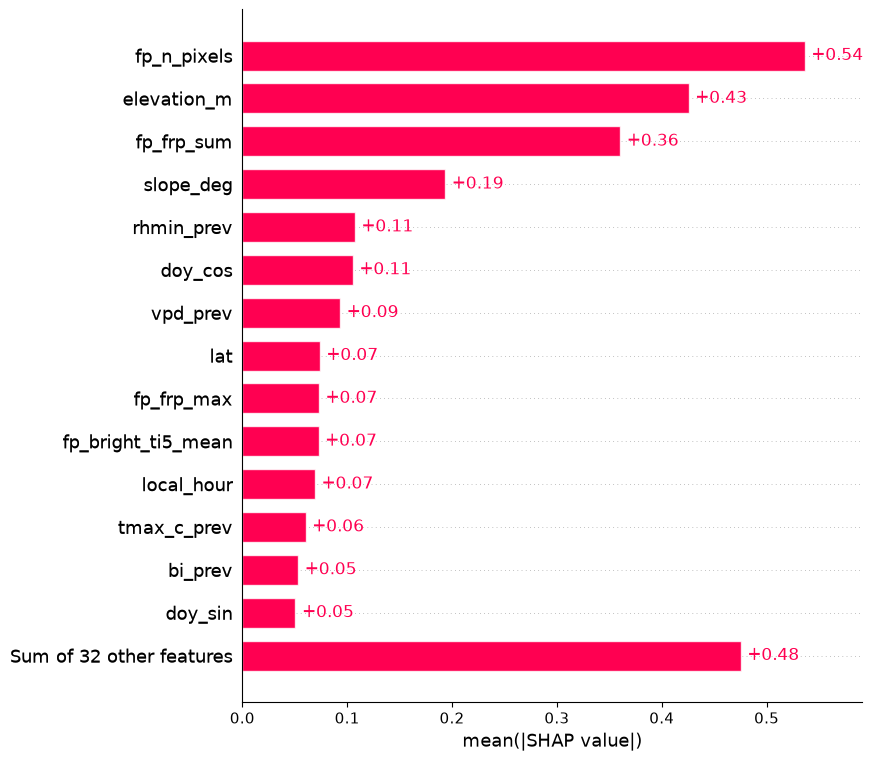

In [20]:
## Step 8 · SHAP: explain XGBoost
import shap

explainer = shap.TreeExplainer(XGB_R_Tuned)

shap_values = explainer(X_test)

shap.plots.bar(shap_values, max_display=15)

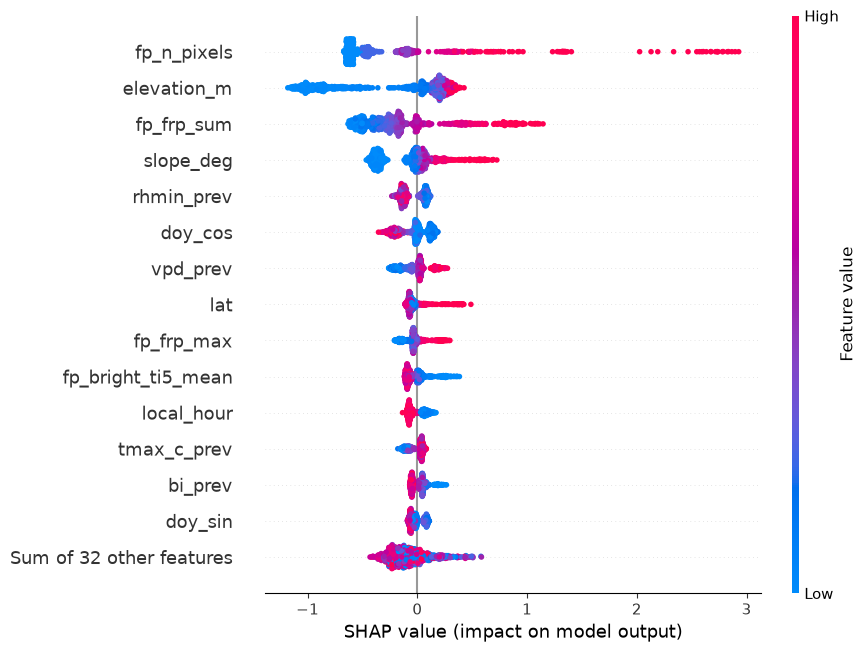

In [21]:
# 2) Beeswarm: one dot per fire per input
#    position left/right = pushed toward small/big, colour = the input's value (red high, blue low)
shap.plots.beeswarm(shap_values, max_display=15)

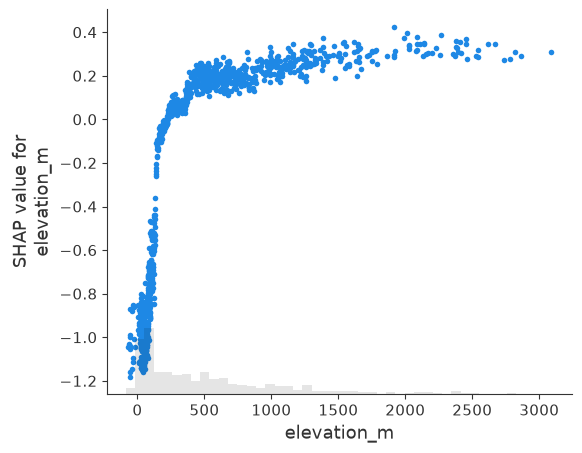

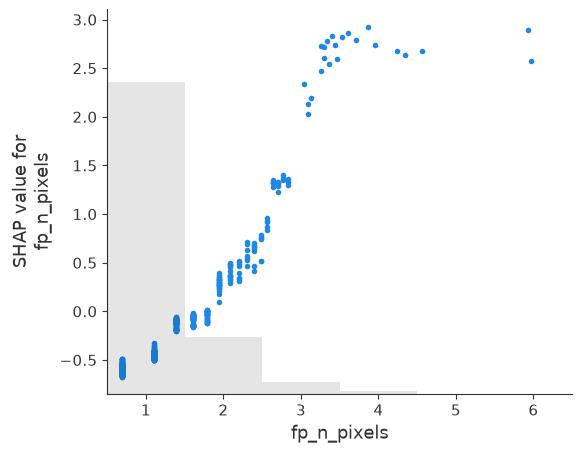

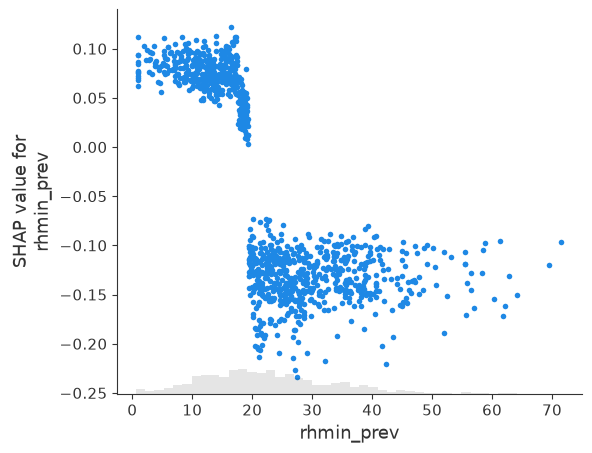

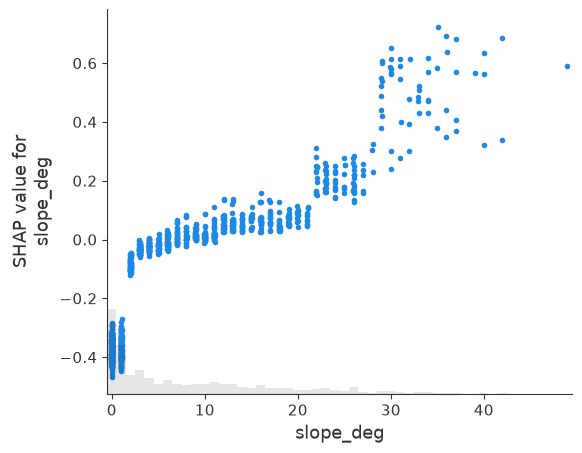

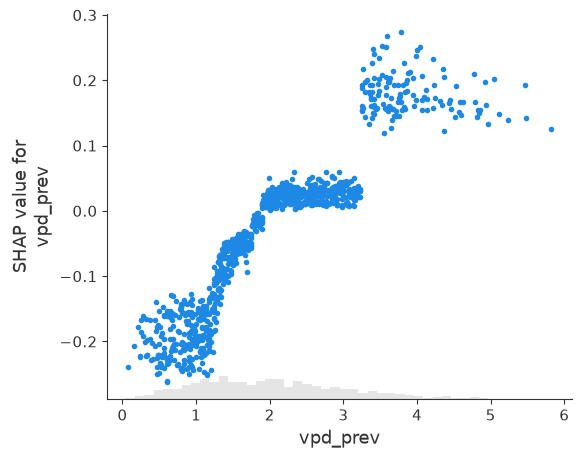

In [22]:
# 3) Dependence plots: compare these with the EBM curves
for col in ["elevation_m", "fp_n_pixels", "rhmin_prev", "slope_deg", "vpd_prev"]:
    shap.plots.scatter(shap_values[:, col])